# Context


A friend is about to open a beer store and has no idea what to put on the shelves. All they have is this dataset of beer ratings and reviews: Beer Ratings and Reviews. You are the analyst they called for help.

The presentation is the first cycle analyses of the CRISP-DS methodology.

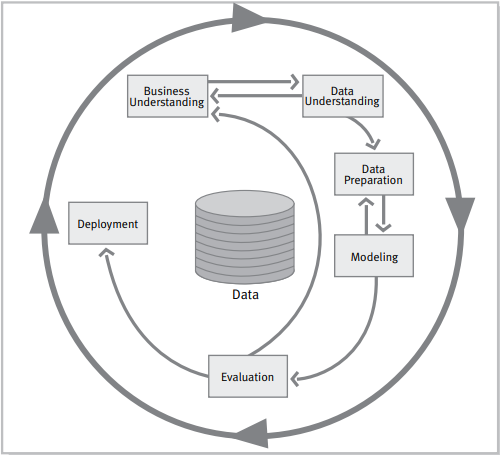


Questions:
- First impressions: how would you describe the dataset to someone who has never seen it?
- Can we trust it? Which issues did you find or suspect in the data quality?
- What drives a good rating? Which factors influence the overall beer rating the most?
- The store decision: which beers would you stock up on, and why?
- Looking ahead: how would you predict the rating of a brand new beer?
- Conclusion

# 1. Understading the data

In [144]:
# Imports

import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [54]:
beer_df = pd.read_csv('../data/train.csv')

## 1.1 Overview


In [55]:
print(f'Columns: \n {beer_df.columns}')

print(f'Data types: \n {beer_df.dtypes}')

Columns: 
 Index(['index', 'beer/ABV', 'beer/beerId', 'beer/brewerId', 'beer/name',
       'beer/style', 'review/appearance', 'review/aroma', 'review/overall',
       'review/palate', 'review/taste', 'review/text', 'review/timeStruct',
       'review/timeUnix', 'user/ageInSeconds', 'user/birthdayRaw',
       'user/birthdayUnix', 'user/gender', 'user/profileName'],
      dtype='str')
Data types: 
 index                  int64
beer/ABV             float64
beer/beerId            int64
beer/brewerId          int64
beer/name                str
beer/style               str
review/appearance    float64
review/aroma         float64
review/overall       float64
review/palate        float64
review/taste         float64
review/text              str
review/timeStruct        str
review/timeUnix        int64
user/ageInSeconds    float64
user/birthdayRaw         str
user/birthdayUnix    float64
user/gender              str
user/profileName         str
dtype: object


**Columns descriptions:**

index: Identifier for the review.

**beer/ABV: Alcohol by volume of the beer**.

**beer/beerId: Unique ID for the beer reviewed.**

beer/brewerId: Unique ID for the brewery.

beer/name: Name of the beer.

**beer/style: Style/type of the beer.**

**review/appearance: Rating of the beer’s appearance (1.0 to 5.0).**

**review/aroma: Rating of the beer’s aroma (1.0 to 5.0).**

**review/overall: Overall rating of the beer (1.0 to 5.0).**

**review/palate: Rating of the beer’s palate (1.0 to 5.0).**

**review/taste: Rating of the beer’s taste (1.0 to 5.0).**

review/text: Text of the review.

review/timeStruct: Structured timestamp for when the review was submitted.

review/timeUnix: Unix timestamp of the review.

user/ageInSeconds: Age of the user in seconds.

user/birthdayRaw: User’s raw birthday information.

user/birthdayUnix: Unix timestamp for the user’s birthday.

user/gender: Gender of the user (if specified).

**user/profileName: Profile name of the user.**

The fields: 

- review/timeStruct can be transformed in datetime. 

- review/timeUnix probably is the same as review/timeStruct but in time unix. 

- user/ageInSeconds is not usual so can be transformed in years. 

- user/birthdayRaw and user/birthdayUnix usually we use age for analyses.

In [56]:
print(f'Rows number: {beer_df.shape[0]}')

Rows number: 37500


Basically the dataset is a composed by three diferents kind of data: beer, review and user. 

- The beer part bright categorical information about the beers, it's like a beer catalog.

- Those beer recevied reviews, so that part bright diferents kind off rates (appearance, arome, overall, palate and taste) and a text resume of the beer.

- Those review were made from users, so that part bright information about the user, like age, birthday, gender and profile name.

In [5]:
beer_df.head()

,index,beer/ABV,beer/beerId,beer/brewerId,beer/name,beer/style,review/appearance,review/aroma,review/overall,review/palate,review/taste,review/text,review/timeStruct,review/timeUnix,user/ageInSeconds,user/birthdayRaw,user/birthdayUnix,user/gender,user/profileName
0,40163,5.0,46634,14338,Chiostro,Herbed / Spiced Beer,4.0,4.0,4.0,4.0,4.0,Pours a clouded gold with a thin white head. N...,"{'min': 38, 'hour': 3, 'mday': 16, 'sec': 10, ...",1229398690,NaN,NaN,NaN,NaN,RblWthACoz
1,8135,11.0,3003,395,Bearded Pat's Barleywine,American Barleywine,4.0,3.5,3.5,3.5,3.0,12oz bottle into 8oz snifter.\t\tDeep ruby red...,"{'min': 38, 'hour': 23, 'mday': 8, 'sec': 58, ...",1218238738,NaN,NaN,NaN,NaN,BeerSox
2,10529,4.7,961,365,Naughty Nellie's Ale,American Pale Ale (APA),3.5,4.0,3.5,3.5,3.5,First enjoyed at the brewpub about 2 years ago...,"{'min': 7, 'hour': 18, 'mday': 26, 'sec': 2, '...",1101492422,NaN,NaN,NaN,Male,mschofield
3,44610,4.4,429,1,Pilsner Urquell,Czech Pilsener,3.0,3.0,2.5,3.0,3.0,First thing I noticed after pouring from green...,"{'min': 7, 'hour': 1, 'mday': 20, 'sec': 5, 'y...",1308532025,1.209827e+09,"Aug 10, 1976",208508400.0,Male,molegar76
4,37062,4.4,4904,1417,Black Sheep Ale (Special),English Pale Ale,4.0,3.0,3.0,3.5,2.5,A: pours an amber with a one finger head but o...,"{'min': 51, 'hour': 6, 'mday': 12, 'sec': 48, ...",1299912708,NaN,NaN,NaN,NaN,Brewbro000


## 1.2 Statistical Overview

### 1.2.1 Null values

In [35]:
100 * beer_df.isnull().sum() / beer_df.shape[0]

index                 0.000000
beer/ABV              0.000000
beer/beerId           0.000000
beer/brewerId         0.000000
beer/name             0.000000
beer/style            0.000000
review/appearance     0.000000
review/aroma          0.000000
review/overall        0.000000
review/palate         0.000000
review/taste          0.000000
review/text           0.026667
review/timeStruct     0.000000
review/timeUnix       0.000000
user/ageInSeconds    79.050667
user/birthdayRaw     79.050667
user/birthdayUnix    79.050667
user/gender          59.162667
user/profileName      0.013333
dtype: float64

Most of the users data are empty. 

Probably columns like user age and birthday will be discarted since almost 80% are nulls. 

Gender field have almost 60% off null values, so we need attention on that.

Review text usually is not necessary for all review, so it's ok that some of them are empty. Same for user profile name.

### 1.2.2 Distribution of the ratings

Before correlating the ratings, we look at how they are distributed.

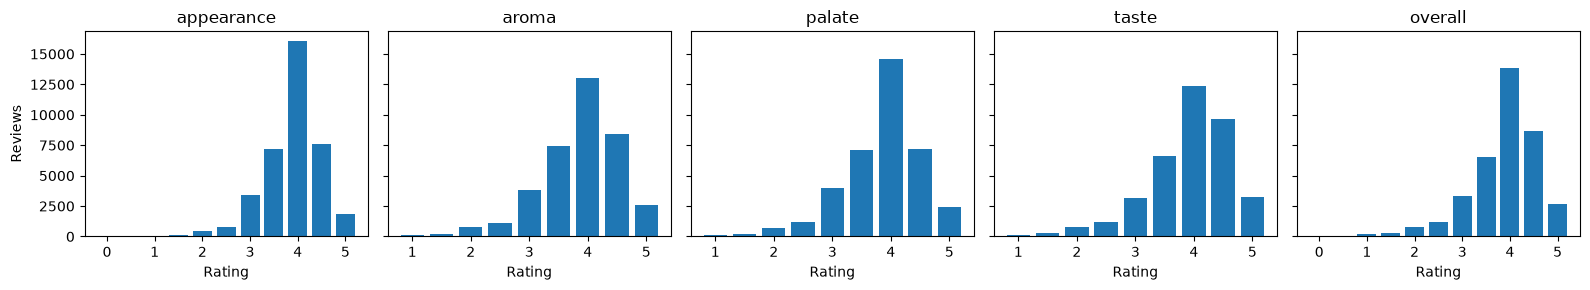

In [97]:
rating_cols = ['review/appearance', 'review/aroma', 'review/palate', 'review/taste', 'review/overall']

fig, axes = plt.subplots(1, 5, figsize=(16, 3), sharey=True)
for ax, col in zip(axes, rating_cols):
    counts = beer_df[col].value_counts().sort_index()
    ax.bar(counts.index, counts.values, width=0.4)
    ax.set_title(col.split('/')[1])
    ax.set_xlabel('Rating')
axes[0].set_ylabel('Reviews')

plt.tight_layout()
plt.show()

### 1.2.3 Reviews over time

Period: 1999-05-10 to 2012-01-11


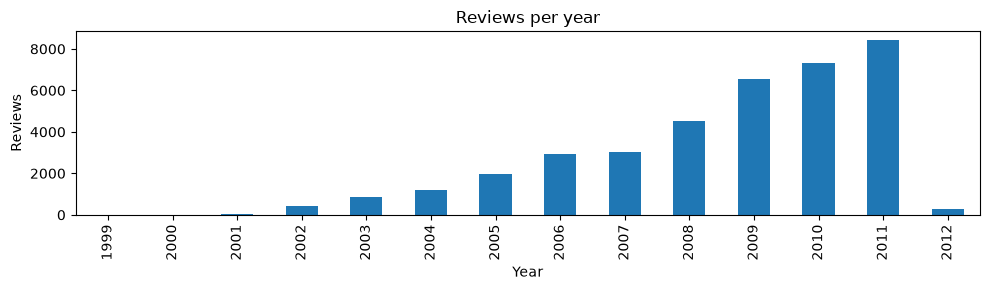

In [99]:
review_dates = pd.to_datetime(beer_df['review/timeUnix'], unit='s')
print(f'Period: {review_dates.min():%Y-%m-%d} to {review_dates.max():%Y-%m-%d}')

ax = review_dates.dt.year.value_counts().sort_index().plot.bar(figsize=(10, 3))
ax.set_xlabel('Year')
ax.set_ylabel('Reviews')
ax.set_title('Reviews per year')

plt.tight_layout()
plt.show()

### 1.2.4 ABV distribution

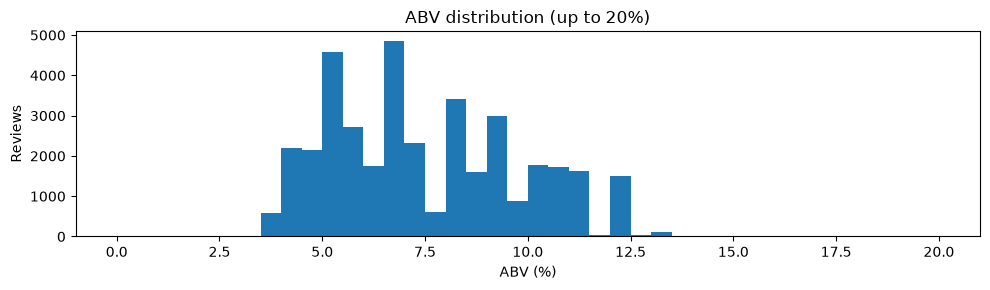

count    37500.00
mean         7.40
std          2.32
min          0.10
25%          5.40
50%          6.90
75%          9.40
max         57.70
Name: beer/ABV, dtype: float64

In [100]:
ax = beer_df['beer/ABV'].plot.hist(bins=40, range=(0, 20), figsize=(10, 3))
ax.set_xlabel('ABV (%)')
ax.set_ylabel('Reviews')
ax.set_title('ABV distribution (up to 20%)')

plt.tight_layout()
plt.show()

beer_df['beer/ABV'].describe().round(2)

The ABV has a median of 6.9%, and half of the reviews are between 5.4% and 9.4%. **Those ABV are usually considered high for beers.** The distribution is skewed to the right: a few beers are very strong, and 5 reviews above 20% were left out of the chart (they are analyzed in the ABV outliers section). It has no nulls.

### 1.2.5 Beer styles

Styles: 95
Top 15 styles: 69% of the reviews
Styles with less than 100 reviews: 43


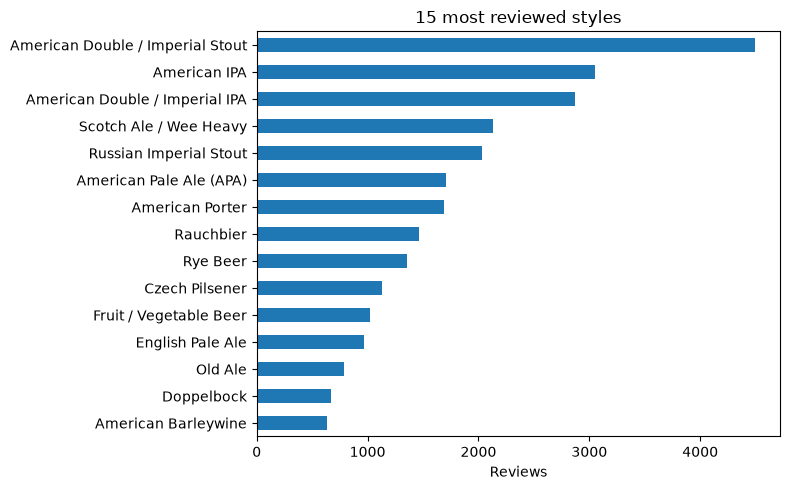

In [101]:
style_counts = beer_df['beer/style'].value_counts()

print(f'Styles: {len(style_counts)}')
print(f'Top 15 styles: {style_counts.head(15).sum() / len(beer_df):.0%} of the reviews')
print(f'Styles with less than 100 reviews: {(style_counts < 100).sum()}')

ax = style_counts.head(15).sort_values().plot.barh(figsize=(8, 5))
ax.set_xlabel('Reviews')
ax.set_ylabel('')
ax.set_title('15 most reviewed styles')

plt.tight_layout()
plt.show()

The 95 styles are very unbalanced: the top 15 have 69% of the reviews, and 43 styles have less than 100 reviews (the smallest ones have only 2 to 7).

The most reviewed styles are mostly strong, dark or hoppy beers (the top 5 are Imperial Stout, IPA, Double IPA, Scotch Ale and Russian Imperial Stout), which is consistent with the ABV above the usual for a beer (median of 6.9%). So the dataset is **not a sample of the whole beer market**, it is the view of a **niche group of reviewers**. This must be remembered when we conclude about what to stock, and the small styles will need to be grouped or filtered by a minimum number of reviews.

# 2. Data quality

Can we trust it? Which issues did we find or suspect in the data quality?

The nulls were already covered above. Here we look for values that are present but wrong or suspicious.

## 2.1 Ratings outside the expected scale

In [36]:
rating_cols = ['review/appearance', 'review/aroma', 'review/palate', 'review/taste', 'review/overall']

beer_df[rating_cols].agg(['min', 'max'])

,review/appearance,review/aroma,review/palate,review/taste,review/overall
min,0.0,1.0,1.0,1.0,0.0
max,5.0,5.0,5.0,5.0,5.0


In [40]:
beer_df[(beer_df[rating_cols] < 1).any(axis=1)][['index', 'beer/name', 'beer/style'] + rating_cols]

,index,beer/name,beer/style,review/appearance,review/aroma,review/palate,review/taste,review/overall
17707,38159,Pub Pils,Czech Pilsener,0.0,2.0,3.0,2.0,0.0


The ratings should go from 1.0 to 5.0, but one review (index 38159, Pub Pils) has **0.0** in appearance and in overall at the same time. Aroma, palate, taste and the text of that row look normal, so 0.0 is probably an input error (or a missing value filled with 0) and not a real rating.

It is a single row in 37,500, so the impact is minimal. Decision: drop row.

## 2.2 Ages outliers

In [128]:
users_df = beer_df.dropna(subset=['user/birthdayUnix']).copy()
users_df['age_at_review'] = (users_df['review/timeUnix'] - users_df['user/birthdayUnix']) / (365.25 * 24 * 3600)

users_df['age_at_review'].describe()

count    7856.000000
mean       31.470294
std        10.521840
min        17.624281
25%        25.129785
50%        29.126052
75%        34.293461
max       110.273665
Name: age_at_review, dtype: float64

In [41]:
outliers_age = users_df[users_df['age_at_review'] > 90]

print(f"Reviews with age above 90: {len(outliers_age)} from {outliers_age['user/profileName'].nunique()} users")
outliers_age['user/birthdayRaw'].value_counts()

Reviews with age above 90: 65 from 4 users


user/birthdayRaw
Jun 16, 1901    35
Jan 1, 1900     25
Feb 28, 1903     3
Jan 13, 1901     2
Name: count, dtype: int64

In [44]:
# ageInSeconds + birthdayUnix is the same for everyone (difference of about 1 second), so ageInSeconds is the age at the data collection, not at the review
collection_time = users_df['user/ageInSeconds'] + users_df['user/birthdayUnix']

pd.to_datetime(collection_time, unit='s').agg(['min', 'max'])

min   2014-12-11 22:04:07
max   2014-12-11 22:04:08
dtype: datetime64[us]

The 65 reviews with more than 90 years (up to 110) come from only 4 users, and their birthdays are `Jan 1, 1900`, `Jun 16, 1901`, `Jan 13, 1901` and `Feb 28, 1903`. Dates like 01/01/1900 are typical default or fake values, so they are not real ages. 

Also, `user/ageInSeconds` is always measured at the same date (the data collection, around Dec/2014), so it is not the age of the user when the review was written.

Together with the ~80% of nulls, this is one more reason to **not use age or birthday** in the analysis. 

The real age at the moment of the review can be calculated (timeUnix - birthdayUnix) and used as a feature, but with 80% of nulls could be a problem.

## 2.3 Gender

In [139]:
beer_df.groupby('user/gender')['user/gender'].agg(nunique='nunique',
                                                  total='count',
                                                  perc= lambda s: round(s.count() / len(beer_df), 4) * 100)

,nunique,total,perc
user/gender,,,
Female,1,245,0.65
Male,1,15069,40.18


We ahve alreadey seen that almost 60% of the gender data are empty, and for those that are not, they are imbalanced. So it is not a column that we will be seen in the next analyses.

## 2.4 Beer ID consistency

In [47]:
beer_attributes = ['beer/name', 'beer/ABV', 'beer/style', 'beer/brewerId']

# For each attribute, how many beerIds have more than one value
(beer_df.groupby('beer/beerId')[beer_attributes].nunique() > 1).sum()

beer/name        0
beer/ABV         0
beer/style       0
beer/brewerId    0
dtype: int64

## 2.5 Is `user/profileName` a unique user identifier?

There is no user id in the dataset, so before talking about "the same user" we need to understand if the profile name can be interpreted as an id. If two different people shared a name, their reviews and attributes would be mixed in the same group.

In [ ]:
user_attributes = ['user/gender', 'user/birthdayRaw', 'user/birthdayUnix', 'user/ageInSeconds']

# Drop null user/profileName
users_group = beer_df.dropna(subset=['user/profileName']).groupby('user/profileName')

print(f'Unique profile names: {users_group.ngroups}')

# For each attribute, how many profile names have more than one value. R: none.
(users_group[user_attributes].nunique() > 1).sum()

Unique profile names: 7441


user/gender          0
user/birthdayRaw     0
user/birthdayUnix    0
user/ageInSeconds    0
dtype: int64

In [59]:
# Names that differ only by case or spaces would be the same person written in different ways
profile_names = beer_df['user/profileName'].dropna()
normalized_names = profile_names.str.strip().str.lower()

print(f'Profile names: {profile_names.nunique()}, after removing case and spaces: {normalized_names.nunique()}')

Profile names: 7441, after removing case and spaces: 7441


**Yes, in practice.** There are 7,441 profile names and each one has a single gender, birthday and age in all of its reviews (no name with more than one value). No name has the attribute filled in some reviews and null in others, and there are no names that differ only by case or spaces. So `profileName` can be used as the user key.

PS: 5 reviews have no profile name. They cannot be assigned to any user and must not be grouped together as if they were one user;

## 2.6 Duplicated review texts

In [84]:
duplicated_text_df = beer_df[beer_df['review/text'].notna() & beer_df.duplicated('review/text', keep=False)].copy()
duplicated_text_df['text_group'] = duplicated_text_df.groupby('review/text').ngroup()

text_groups = duplicated_text_df.groupby('text_group').agg(
    text=('review/text', lambda s: s.iloc[0]),
    users=('user/profileName', lambda s: ' / '.join(s)),
    beers=('beer/name', lambda s: ' / '.join(s)),
    beer_ids=('beer/beerId', 'nunique'),
    days_between=('review/timeUnix', lambda s: round((s.max() - s.min()) / (24 * 3600), 1)),
)
text_groups['same_user'] = duplicated_text_df.groupby('text_group')['user/profileName'].nunique() == 1
text_groups['same_beer'] = duplicated_text_df.groupby('text_group')['beer/name'].nunique() == 1

text_groups

,text,users,beers,beer_ids,days_between,same_user,same_beer
text_group,,,,,,,
0,"A - Dark Clear fairly clear amber, good head, ...",srandycarter / LiquidBread219,Smooth Hoperator / Smooth Hoperator,1,555.7,False,True
1,A - hazy (perhaps slightly from bottle conditi...,scoobybrew / scoobybrew,Mephistopheles' Metamorphosis / Mephistopheles...,2,32.9,True,True
2,"Appearance: amber-hued body with a thinnish, n...",CampusCrew / CampusCrew,Aecht Schlenkerla Rauchbier MÃ¤rzen / Aecht Sc...,2,271.0,True,False
3,Bottle in the Lot Airlines business class loun...,Travlr / Travlr,O.K. Beer / Okocim Beer,2,0.0,True,False
4,Bought a bottle of this from the brewery the o...,iceviper22 / iceviper22,Stoudt's Brewer's Reserve Scotch Style Ale / S...,2,79.7,True,False
5,Nice dark amber color with red and gold hues p...,barleywinefiend / skillerified,Pike Kilt Lifter Scotch Style Ale / Pike Kilt ...,1,307.2,False,True
6,"The beer has a bit of a reddish color to it, w...",Boto / Muller,Stoudt's Scarlet Lady ESB / Stoudt's Scarlet L...,1,2222.4,False,True
7,This is my first real maibock so I may be bias...,Muller / Gasp100,Stoudt's Blonde Double MaiBock / Stoudt's Blon...,1,1919.0,False,True


There are 8 repeated texts (16 reviews), and they have two origins:

- Same user, 4 cases.
- Different users, same beer, 4 cases.

It is only 16 reviews, so we **keep them**. If we use the text in an NLP step, we should drop the repeated ones. 

If the dataset increase, same kind of alert can be develop to detect spam.

## 2.7 ABV outliers

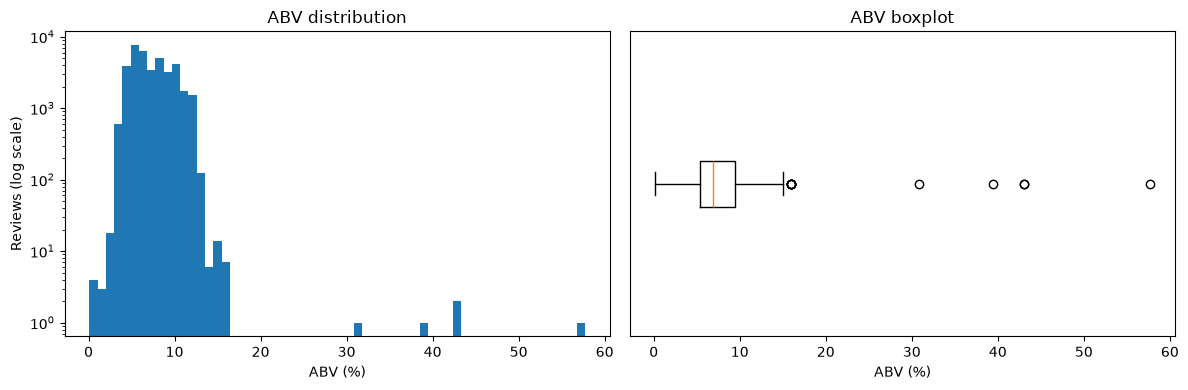

In [126]:
fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(12, 4))

ax_hist.hist(beer_df['beer/ABV'], bins=60)
ax_hist.set_yscale('log')
ax_hist.set_xlabel('ABV (%)')
ax_hist.set_ylabel('Reviews (log scale)')
ax_hist.set_title('ABV distribution')

ax_box.boxplot(beer_df['beer/ABV'], orientation='horizontal')
ax_box.set_xlabel('ABV (%)')
ax_box.set_yticks([])
ax_box.set_title('ABV boxplot')

plt.tight_layout()
plt.show()

In [90]:
extreme_abv = beer_df[(beer_df['beer/ABV'] > 15) | (beer_df['beer/ABV'] <= 1)]

extreme_abv.groupby(['beer/beerId', 'beer/name', 'beer/style', 'beer/ABV']).size().rename('reviews').reset_index().sort_values('beer/ABV')

,beer/beerId,beer/name,beer/style,beer/ABV,reviews
7,59239,Amstel Malt,Low Alcohol Beer,0.10,2
3,52123,Karmi Classic,Euro Dark Lager,0.50,1
4,53523,Bernard S &#269;istou Hlavou,Low Alcohol Beer,0.50,1
0,45774,Jeffersons Reserve Big Fella Bourbon Barrel Stout,American Double / Imperial Stout,16.00,2
1,47421,Schorschbock,Doppelbock,16.00,4
8,71004,Schorsch Weizen 16%,Weizenbock,16.00,1
2,51466,SchorschbrÃ¤u Schorschbock 31%,Eisbock,30.86,1
5,55712,SchorschbrÃ¤u Schorschbock 40%,Eisbock,39.44,1
6,57856,SchorschbrÃ¤u Schorschbock 43%,Eisbock,43.00,2
9,73368,SchorschbrÃ¤u Schorschbock 57%,Eisbock,57.70,1


## 2.8 Summary: can we trust the data?

ABV goes from 0.1% to 57.7%, with median 6.9%. The chart shows a long tail on the right, but the extreme values are **real, not errors**.

There are no nulls in ABV. Decision: keep them, but they are outliers for the modeling step, where a linear model can be pulled by them (use a log scale or cap the values).

Mostly yes, with some care. The ratings, beer information and timestamps are consistent, and the issues found are small or concentrated in the user columns.

| Issue | Size | Decision |
|---|---|---|
| Nulls in age, birthday and gender | ~79% (age, birthday) | Do not use age and birthday |
| Outliers ages (default birthdays) | 65 reviews, 4 users | One more reason to not use age |
| Nulls in gender and imbalanced | ~60% nulls and very imbalanced data | User with care |
| Rating 0.0 outside the 1.0-5.0 scale | 1 review | Drop the row|
| Repeated review texts | 16 reviews | Keep, drop only if we use the text |
| No user ID, 5 reviews without profileName | 5 reviews | `profileName` works as the user key (consistent attributes); ignore those 5 in user analysis |
| Same name with different beerId | 27 names, 1,175 reviews | It is not a problem, but always use `beerId`, not the name |
| Extreme ABV values | 5 reviews above 20%, 4 at 1% or less | Real values (high alcohol Eisbock, low alcohol beers). Keep, treat as outliers in the model |

# 3. What drives a good rating?

Which factors influence the overall beer rating the most?

We start with the 4 sub-ratings (appearance, aroma, palate and taste). The characteristics of the beer (style, ABV) come next.

## 3.1 Data for the analysis

We apply the decision of the data quality section about the 0.0 rating (that review is dropped).

In [93]:
clean_df = beer_df[(beer_df[rating_cols] >= 1).all(axis=1)].copy()

print(f'Reviews: {len(beer_df)} -> {len(clean_df)}')

Reviews: 37500 -> 37499


It will not make real impact, but with we imagine that the dataset is growning in time, it is something that we have to clean.

## 3.2 Correlation between the ratings

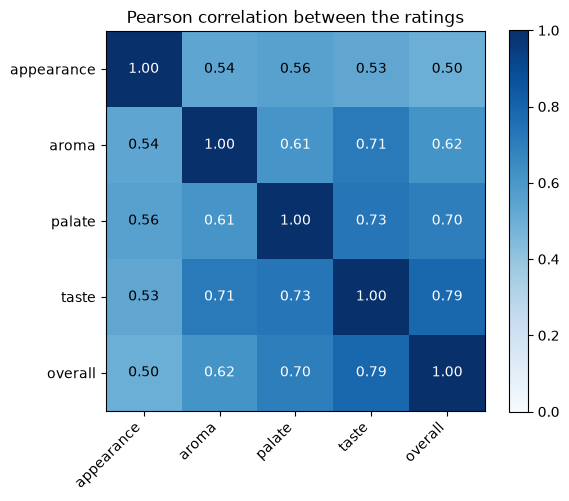

In [103]:
# Pearson: the relation between the ratings is close to linear, the same assumption of the linear regression below
corr = clean_df[rating_cols].corr()
labels = [col.split('/')[1] for col in rating_cols]

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, vmin=0, vmax=1, cmap='Blues')
ax.set_xticks(range(len(labels)), labels, rotation=45, ha='right')
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', color='white' if corr.iloc[i, j] > 0.6 else 'black')
fig.colorbar(im)
ax.set_title('Pearson correlation between the ratings')

plt.tight_layout()
plt.show()

**Taste** is the rating most related to the overall (0.79), followed by palate (0.70), aroma (0.62) and appearance (0.50).

The sub-ratings are also related to each other, mainly taste with palate (0.73) and with aroma (0.71), which makes sense because the user rates them together. Appearance is the most independent one (0.53 to 0.56 with the others). So we should not read the correlations alone: part of the relation of aroma or palate with the overall may pass through taste. The regression separates that.

## 3.3 Linear regression

Model: `overall ~ appearance + aroma + palate + taste`.

The variables are standardized (mean 0 and standard deviation 1), so the coefficients are comparable between them: each one is the change of the overall, in standard deviations, for +1 standard deviation of that rating, keeping the others fixed. The VIF checks if the correlation between the ratings is a problem for the interpretation (above 5 to 10 would be).

In [ ]:
features = ['review/appearance', 'review/aroma', 'review/palate', 'review/taste']
target = 'review/overall'

X = clean_df[features]
X_std = (X - X.mean()) / X.std()
y_std = (clean_df[target] - clean_df[target].mean()) / clean_df[target].std()

model = sm.OLS(y_std, sm.add_constant(X_std)).fit() # Ordinary Least Squares

conf_int = model.conf_int().loc[features]
coefficients = pd.DataFrame({
    'coef': model.params[features],
    'ci_low': conf_int[0],
    'ci_high': conf_int[1],
    'vif': [variance_inflation_factor(sm.add_constant(X).values, i + 1) for i in range(len(features))],
}).sort_values('coef', ascending=False)

print(f'R2: {model.rsquared:.3f}')
coefficients.round(3)

R2: 0.653


,coef,ci_low,ci_high,vif
review/taste,0.546,0.536,0.556,2.865
review/palate,0.237,0.228,0.246,2.383
review/aroma,0.059,0.050,0.068,2.213
review/appearance,0.044,0.037,0.052,1.605


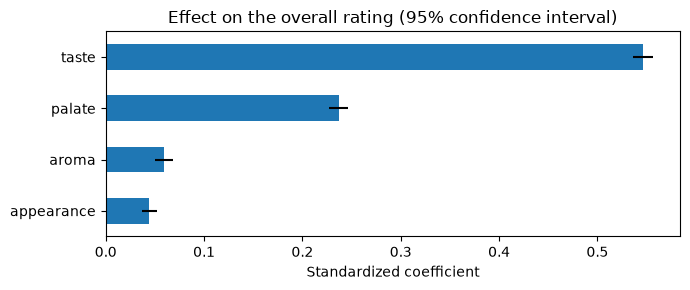

In [105]:
errors = (coefficients['ci_high'] - coefficients['ci_low']) / 2

ax = coefficients['coef'].plot.barh(xerr=errors, figsize=(7, 3))
ax.invert_yaxis()
ax.set_yticklabels([col.split('/')[1] for col in coefficients.index])
ax.set_xlabel('Standardized coefficient')
ax.set_title('Effect on the overall rating (95% confidence interval)')

plt.tight_layout()
plt.show()

In [106]:
# R2 of a model with only one rating (square of the Pearson correlation)
(clean_df[features].corrwith(clean_df[target]) ** 2).sort_values(ascending=False)

review/taste         0.616572
review/palate        0.486273
review/aroma         0.379486
review/appearance    0.248251
dtype: float64

The model explains **65% of the variance** of the overall rating (R2 = 0.65). **Taste is by far the most important** (0.55), then palate (0.24). Aroma (0.06) and appearance (0.04) have a small effect, even if the confidence intervals do not cross zero (with 37 thousand reviews, almost everything is significant). All the VIF are below 3, so the correlation between the ratings is not a problem for reading the coefficients.

Taste alone explains 62% of the variance, and the four ratings together 65%, so the other three add very little. In practice, the overall rating is mostly the taste, with palate (mouthfeel) as the second factor. Aroma and appearance matter little, and part of their correlation with the overall (0.62 and 0.50) is explained by taste.

Care with this conclusion:

- The ratings come from the same review, so this is what the users value, not a cause. It does not tell what to stock and it cannot predict a new beer, because we would not have the sub-ratings before the review. For that we need the characteristics of the beer.
- The model is linear, but the ratings are discrete and limited between 1 and 5.

## 3.4 Beer characteristics

Now we look at the characteristics of the beer. Different from the sub-ratings, they are known before anyone reviews the beer, so they can say something about a beer we never saw. We start with the style.

### 3.4.1 Style

Styles with 100+ reviews: 52 (95% of the reviews)
Styles above the global mean: 11, below: 41


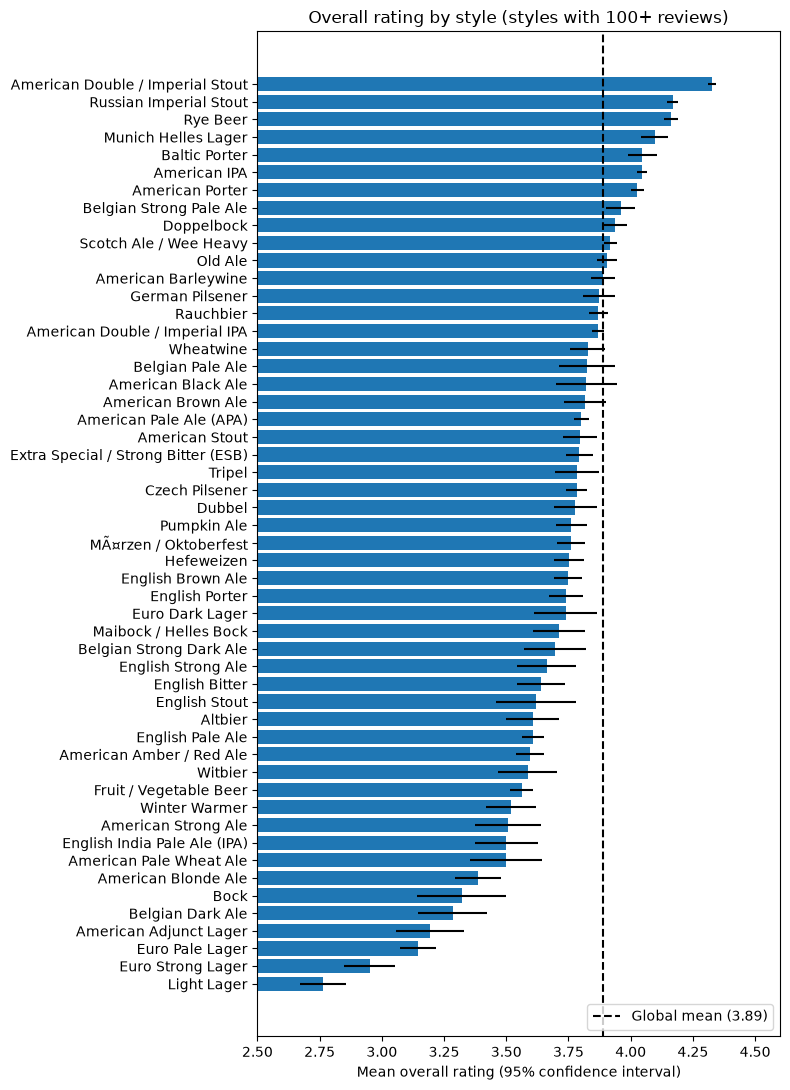

In [107]:
style_stats = clean_df.groupby('beer/style')['review/overall'].agg(['mean', 'std', 'count'])
style_stats['ci'] = 1.96 * style_stats['std'] / style_stats['count'] ** 0.5

# Styles with few reviews have a very noisy mean
style_stats = style_stats[style_stats['count'] >= 100].sort_values('mean')
global_mean = clean_df['review/overall'].mean()

print(f"Styles with 100+ reviews: {len(style_stats)} ({style_stats['count'].sum() / len(clean_df):.0%} of the reviews)")
print(f"Styles above the global mean: {(style_stats['mean'] > global_mean).sum()}, below: {(style_stats['mean'] < global_mean).sum()}")

fig, ax = plt.subplots(figsize=(8, 11))
ax.barh(style_stats.index, style_stats['mean'], xerr=style_stats['ci'])
ax.axvline(global_mean, color='black', linestyle='--', label=f'Global mean ({global_mean:.2f})')
ax.set_xlim(2.5, 4.6)
ax.set_xlabel('Mean overall rating (95% confidence interval)')
ax.set_title('Overall rating by style (styles with 100+ reviews)')
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

The style makes a big difference. Among the 52 styles with 100 or more reviews (95% of the reviews), the mean rating goes from **2.76** (Light Lager) to **4.33** (American Double / Imperial Stout), a difference of 1.56 points, much bigger than the confidence intervals (at most 0.14).

- **Bottom:** the pale and adjunct lagers (Light Lager 2.76, Euro Strong Lager 2.95, Euro Pale Lager 3.14, American Adjunct Lager 3.19).
- **Top:** the strong and dark beers (Imperial Stout 4.33, Russian Imperial Stout 4.17, Rye Beer 4.16), plus the American IPA (4.05), the American Porter (4.03) and the Munich Helles Lager (4.10), the only light beer among the best.

41 of the 52 styles are below the global mean (3.89). The mean is pulled up by a few very big and well rated styles (the Imperial Stout alone has 4,495 reviews), so the global mean is not a good reference to say if a style is "good".

Care: this is the opinion of a community of craft beer reviewers (see the styles in the overview), so the lagers can be rated low because of who is rating them. The 43 styles with less than 100 reviews were left out (5% of the reviews).

**TO DO:**

Next steps for the characteristics of the beer:

1. **ABV x rating.** Mean rating by ABV range, and then the same comparison **inside each style**. A first look suggests that the ABV effect is mostly the style effect (the strong beers are Imperial Stouts, Scotch Ales and Double IPAs, which are well rated), so we need to confirm it before saying that the ABV matters.
2. **Brewery x rating.** Ranking of the breweries with a minimum number of reviews. There are 212 breweries, the 10 biggest have 76% of the reviews and 35% of them have less than 5, so the means of the small ones are noisy.
3. **Joint model.** Style, ABV and brewery together to see how much of the rating the characteristics of the beer explain, and which of them matter more when the others are controlled.

# 4. The store decision

Which beers would we stock up on, and why?

Now the unit of the analysis is the **beer** (`beerId`), not the review. An important limit: the dataset has only ratings, it has no price, sales, margin or availability. So what we can answer is **which beers the reviewers rate best**, and this is a recommendation of quality, not of profit.

## 4.1 Ranking beers with few reviews

In [ ]:
beer_stats = clean_df.groupby('beer/beerId').agg(
    name=('beer/name', 'first'),
    style=('beer/style', 'first'),
    abv=('beer/ABV', 'first'),
    reviews=('review/overall', 'size'),
    mean=('review/overall', 'mean'),
    std=('review/overall', 'std'),
)

# The simplest ranking: the mean rating of each beer
beer_stats.sort_values('mean', ascending=False).head(5).round(2)

,name,style,abv,reviews,mean,std
beer/beerId,,,,,,
38766,Oak Aged Los Diablos Del Paso,American IPA,8.0,1,5.0,NaN
36039,Calapooia Barleywine,American Barleywine,11.0,1,5.0,NaN
32306,Farmhouse Ale,Saison / Farmhouse Ale,5.9,2,5.0,0.0
40448,BourbonDog ESB,Extra Special / Strong Bitter (ESB),5.5,1,5.0,NaN
72007,Saisonnaire,Saison / Farmhouse Ale,4.0,1,5.0,NaN


The top of the ranking by the raw mean is full of beers with **1 or 2 reviews** and a perfect 5.0. It is the opinion of one person, so we cannot trust it (most beers have few reviews: the median is 2).

To fix it we use a **Bayesian average**: each beer mean is pulled to the global mean, and the fewer reviews the beer has, the stronger the pull. A weight of 30 means that a beer needs about 30 reviews for its own mean to count as much as the global one. With 30 or more reviews there are 173 beers, which hold 83% of all the reviews.

In [140]:
global_mean = clean_df['review/overall'].mean()


def bayesian_mean(stats, weight):
    return (stats['reviews'] * stats['mean'] + weight * global_mean) / (stats['reviews'] + weight)


beer_stats['score'] = bayesian_mean(beer_stats, 30)

beer_stats.sort_values('score', ascending=False).head(10).round(2)

,name,style,abv,reviews,mean,std,score
beer/beerId,,,,,,,
47658,Founders CBS Imperial Stout,American Double / Imperial Stout,10.6,482,4.58,0.43,4.54
19960,Founders KBS (Kentucky Breakfast Stout),American Double / Imperial Stout,11.2,1441,4.39,0.56,4.38
11757,Founders Breakfast Stout,American Double / Imperial Stout,8.3,1883,4.36,0.50,4.35
16074,Founders Red's Rye PA,Rye Beer,6.6,1051,4.21,0.48,4.20
21822,Founders Imperial Stout,Russian Imperial Stout,10.5,805,4.21,0.45,4.20
7348,Founders Porter,American Porter,6.5,675,4.21,0.41,4.20
20478,Founders Harvest Ale,American IPA,6.5,492,4.21,0.48,4.19
54827,Founders Black Biscuit,Old Ale,10.5,115,4.27,0.48,4.19
21704,Aecht Schlenkerla Fastenbier,Rauchbier,5.5,62,4.31,0.48,4.18


In [141]:
# Does the top 20 change a lot with the weight?
top_20 = {weight: set(bayesian_mean(beer_stats, weight).nlargest(20).index) for weight in (10, 30, 50, 100)}

for weight in (10, 50, 100):
    print(f'Top 20 with weight 30 vs weight {weight}: {len(top_20[30] & top_20[weight])} beers in common')

Top 20 with weight 30 vs weight 10: 14 beers in common
Top 20 with weight 30 vs weight 50: 18 beers in common
Top 20 with weight 30 vs weight 100: 16 beers in common


With the adjustment the top is made of beers with a lot of reviews and high rating, led by *Founders CBS Imperial Stout* (4.54), *KBS* (4.38) and *Breakfast Stout* (4.35). Nine of the first 10 are from Founders.

The ranking is reasonably robust to the weight: 14 to 18 of the 20 first beers are the same when we change the weight from 30 to 10, 50 or 100. The beers that change are the ones with few reviews, which is expected.

Some care with the names: they are not unique (there are generic names like *Hefeweizen* with more than one ID) and some have encoding problems (for example *Founders RÃ¼bÃ¦us*), so we should always identify the beer by `beerId`.

## 4.2 Quality x popularity

A good rating is not enough, the confidence in the rating also matters, and the number of reviews is a sign of how known the beer is. We cross the two for the 349 beers with 10 or more reviews and separate them in groups:

- **Star:** score of 4.0 or more and 100 or more reviews. The base of the shelf.
- **Potential:** score of 4.0 or more and less than 100 reviews. A differentiator, but with a less certain rating.
- **Popular, above average:** 100 or more reviews and a score between the global mean and 4.0. Well known and solid beers, a good second line for the shelf.
- **Popular, below average:** 100 or more reviews and score below the global mean. To avoid or to stock little.

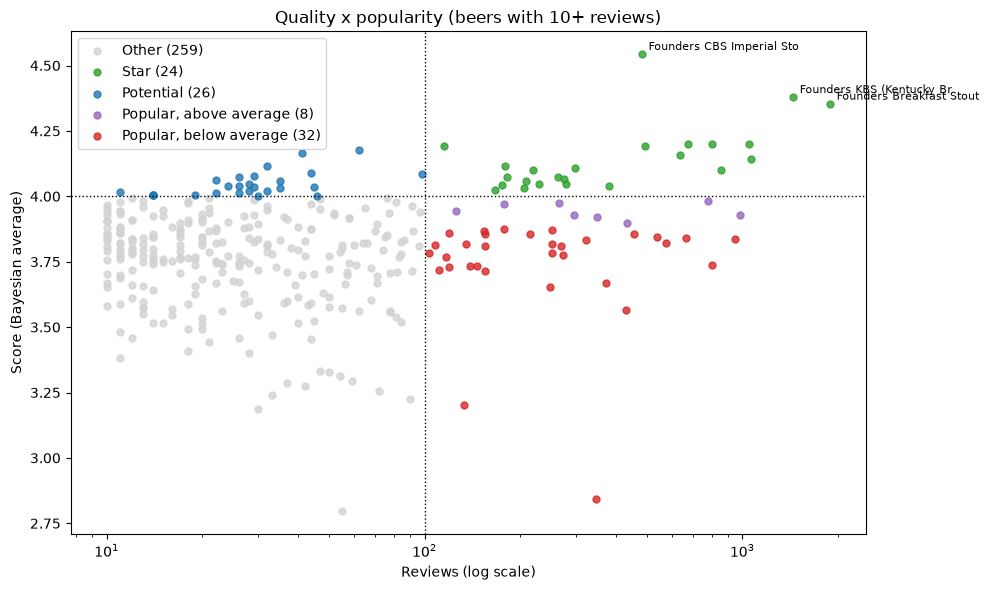

In [115]:
eligible = beer_stats[beer_stats['reviews'] >= 10].copy()


def classify(beer):
    if beer['score'] >= 4.0:
        return 'Star' if beer['reviews'] >= 100 else 'Potential'
    if beer['reviews'] >= 100:
        return 'Popular, above average' if beer['score'] >= global_mean else 'Popular, below average'
    return 'Other'


eligible['group'] = eligible.apply(classify, axis=1)

colors = {'Other': 'lightgray', 'Star': 'tab:green', 'Potential': 'tab:blue', 'Popular, above average': 'tab:purple', 'Popular, below average': 'tab:red'}

fig, ax = plt.subplots(figsize=(10, 6))
for group, color in colors.items():
    subset = eligible[eligible['group'] == group]
    ax.scatter(subset['reviews'], subset['score'], c=color, s=25, alpha=0.8, label=f'{group} ({len(subset)})')

ax.axhline(4.0, color='black', linestyle=':', linewidth=1)
ax.axvline(100, color='black', linestyle=':', linewidth=1)
for _, beer in eligible.nlargest(3, 'score').iterrows():
    ax.annotate(beer['name'][:25], (beer['reviews'], beer['score']), fontsize=8, xytext=(5, 3), textcoords='offset points')

ax.set_xscale('log')
ax.set_xlabel('Reviews (log scale)')
ax.set_ylabel('Score (Bayesian average)')
ax.set_title('Quality x popularity (beers with 10+ reviews)')
ax.legend()

plt.tight_layout()
plt.show()

In [116]:
columns = ['name', 'style', 'abv', 'reviews', 'mean', 'std', 'score']

print('Stars (top 10 by score)')
display(eligible[eligible['group'] == 'Star'].nlargest(10, 'score')[columns].round(2))

print('Potentials (top 10 by score)')
display(eligible[eligible['group'] == 'Potential'].nlargest(10, 'score')[columns].round(2))

print('Popular, above average (all)')
display(eligible[eligible['group'] == 'Popular, above average'].sort_values('score', ascending=False)[columns].round(2))

print('Popular, below average (10 with more reviews)')
display(eligible[eligible['group'] == 'Popular, below average'].nlargest(10, 'reviews')[columns].round(2))

Stars (top 10 by score)


,name,style,abv,reviews,mean,std,score
beer/beerId,,,,,,,
47658,Founders CBS Imperial Stout,American Double / Imperial Stout,10.6,482,4.58,0.43,4.54
19960,Founders KBS (Kentucky Breakfast Stout),American Double / Imperial Stout,11.2,1441,4.39,0.56,4.38
11757,Founders Breakfast Stout,American Double / Imperial Stout,8.3,1883,4.36,0.50,4.35
16074,Founders Red's Rye PA,Rye Beer,6.6,1051,4.21,0.48,4.20
21822,Founders Imperial Stout,Russian Imperial Stout,10.5,805,4.21,0.45,4.20
7348,Founders Porter,American Porter,6.5,675,4.21,0.41,4.20
20478,Founders Harvest Ale,American IPA,6.5,492,4.21,0.48,4.19
54827,Founders Black Biscuit,Old Ale,10.5,115,4.27,0.48,4.19
33644,B.O.R.I.S. The Crusher Oatmeal-Imperial Stout,Russian Imperial Stout,9.4,636,4.17,0.50,4.16


Potentials (top 10 by score)


,name,style,abv,reviews,mean,std,score
beer/beerId,,,,,,,
21704,Aecht Schlenkerla Fastenbier,Rauchbier,5.50,62,4.31,0.48,4.18
69894,Founders Cashew Mountain Brown,American Brown Ale,10.00,41,4.37,0.49,4.16
72827,Barrel Aged Naked Evil,English Barleywine,11.30,32,4.33,0.43,4.12
34362,Stoudt's Barrel Aged Fat Dog (Imperial Oatmea...,American Double / Imperial Stout,9.00,44,4.23,0.50,4.09
51483,Sue,American Porter,9.00,98,4.14,0.44,4.08
507,Hefeweizen,Hefeweizen,6.00,29,4.28,0.39,4.08
49237,Founders Barrel Aged Imperial Stout,American Double / Imperial Stout,10.00,26,4.29,0.38,4.07
31703,Arquebus,English Barleywine,10.75,22,4.30,0.50,4.06
3517,Stoudt's India Pale Ale,American IPA,7.50,35,4.20,0.44,4.06


Popular, above average (all)


,name,style,abv,reviews,mean,std,score
beer/beerId,,,,,,,
35036,Founders Backwoods Bastard,Scotch Ale / Wee Heavy,10.2,778,3.98,0.62,3.98
20539,Stoudt's Fat Dog (Imperial Oatmeal Stout),American Double / Imperial Stout,9.0,265,3.98,0.52,3.97
28350,5 Day IPA,American IPA,6.1,178,3.99,0.49,3.97
25414,Caldera Pale Ale,American Pale Ale (APA),5.5,126,3.96,0.51,3.94
7463,Founders Dirty Bastard,Scotch Ale / Wee Heavy,8.5,983,3.93,0.53,3.93
1550,Stoudts American Pale Ale,American Pale Ale (APA),5.0,296,3.93,0.58,3.93
60511,Founders Nemesis 2010,American Barleywine,12.0,348,3.92,0.58,3.92
1324,Aecht Schlenkerla Rauchbier Urbock,Rauchbier,6.6,433,3.90,0.70,3.90


Popular, below average (10 with more reviews)


,name,style,abv,reviews,mean,std,score
beer/beerId,,,,,,,
429,Pilsner Urquell,Czech Pilsener,4.4,947,3.83,0.71,3.84
17538,Founders Devil Dancer,American Double / Imperial IPA,12.0,800,3.73,0.68,3.74
727,Aecht Schlenkerla Rauchbier MÃ¤rzen,Rauchbier,5.4,665,3.84,0.75,3.84
24905,Founders Curmudgeon (Old Ale),Old Ale,9.8,574,3.82,0.56,3.82
20470,Stoudt's Double IPA (India Pale Ale),American Double / Imperial IPA,10.0,538,3.84,0.62,3.85
4073,Founders Pale Ale,American Pale Ale (APA),5.4,457,3.85,0.56,3.85
3824,Monty Python's Holy Grail Ale,English Pale Ale,4.7,429,3.54,0.70,3.57
48911,Founders Cerise,Fruit / Vegetable Beer,6.5,372,3.65,0.61,3.67
436,Amstel Light,Light Lager,3.5,345,2.75,0.91,2.84


Among the 349 beers with 10 or more reviews there are **24 stars**, **26 Potentials**, **8 popular beers above the average** and **32 popular beers below the average**. Half of the **stars** are from Founders, so the shelf made only by the ranking would be very concentrated in one brewery and in a few strong styles.

The **Potentials** are interesting for differentiation, but with 20 to 98 reviews the rating has a wider margin of error, so they are a smaller bet.

The **popular beers above the average** (score between 3.90 and 3.98), with 126 to 983 reviews, but they are better rated and more consistent (mean standard deviation of 0.56, against 0.64 for the ones below the average). Examples are *Founders Backwoods Bastard* (778 reviews, 3.98), *Founders Dirty Bastard* (983 reviews, 3.93), *Stoudt's Fat Dog* (3.97) and *5 Day IPA* (3.97). They just miss the 4.0 of the stars, so they are a solid second line and should have priority over the popular beers below the average.

The **popular beers below the average** include very well known beers, like *Pilsner Urquell* (947 reviews, 3.83) and *Aecht Schlenkerla Rauchbier Märzen* (665 reviews, 3.84), and *Amstel Light* (345 reviews, 2.75) is the lowest. Their ratings are also more spread: the standard deviation is between 0.56 and 0.91, against 0.41 to 0.56 for the stars. The reviewers of this dataset are craft beer enthusiasts, and a beer can sell well even when this group does not rate it high, so we should not remove them from the shelf only because of this.

**What we recommend with this data:** the stars as the base of the shelf, the popular beers above the average as a second line, some Potentials to differentiate, and a check with price and local demand (that we do not have) before the final decision. Next we should balance the list by style and check if the rating of each beer is stable or falling over time.

# 5. Looking ahead

How would we predict the rating of a brand new beer?

A new beer has no reviews yet, so the simplest prediction is the **mean rating of its style** (baseline). The brewery and the ABV are left for the machine learning step (see the TO DO).

In [120]:
style_mean = clean_df.groupby('beer/style')['review/overall'].mean()

style_mean[['Light Lager', 'American IPA', 'American Double / Imperial Stout']].round(2)

beer/style
Light Lager                         2.76
American IPA                        4.05
American Double / Imperial Stout    4.33
Name: review/overall, dtype: float64

Does it work for a beer that the model never saw? We split the **beers** in 5 groups at random, so all the reviews of a beer stay together. For each group, we calculate the style means with the other 4 groups and use them to predict its reviews. At the end, we have a prediction for every review that was made without seeing its beer.

In [ ]:
beer_ids = clean_df['beer/beerId'].drop_duplicates().sample(frac=1, random_state=42)
group_of_beer = pd.Series(range(len(beer_ids)), index=beer_ids) % 5
group = clean_df['beer/beerId'].map(group_of_beer)

predicted = pd.Series(index=clean_df.index, dtype=float)
for g in range(5):
    train, test = clean_df[group != g], clean_df[group == g]
    train_style_mean = train.groupby('beer/style')['review/overall'].mean()
    predicted[test.index] = test['beer/style'].map(train_style_mean).fillna(train['review/overall'].mean())

rating = clean_df['review/overall']
rmse = lambda prediction: ((rating - prediction) ** 2).mean() ** 0.5 # Root Mean Square Error

print(f'Error (RMSE) always predicting the global mean: {rmse(rating.mean()):.3f}')
print(f'Error (RMSE) predicting the mean of the style: {rmse(predicted):.3f}')

Error (RMSE) always predicting the global mean: 0.700
Error (RMSE) predicting the mean of the style: 0.659


A new beer is expected to get the mean of its style: about **4.33** for an Imperial Stout, **4.05** for an IPA and **2.76** for a Light Lager.

Predicting with the style mean instead of the global mean lowers the error from 0.70 to 0.66 (**6% less**). The result is almost the same with other random splits (between 0.655 and 0.662). It is a small gain, which agrees with what we saw before: the style explains only part of the rating, and the rest depends on the beer itself and on who rates it.

Limits: the 17 styles with less than 20 reviews (0.4% of the reviews) have a mean that we cannot trust, and the error of 0.66 is for a single review, which also has the difference between the people who rate. It does not use the brewery or the ABV. This is the **reference that a machine learning model needs to beat** (see the TO DO), and when the beer receives its first reviews, we should replace this prediction by the Bayesian average of the beer, as in the ranking.

## TO DO

Machine learning model for a new beer. The mean of the style (error of 0.66) is the reference to beat.

- **Features:** style, brewery, ABV and words of the beer name (for example *Imperial*, *Barrel Aged*, *Double*). Rare categories are grouped in an "other" category.
- **Models:** a Ridge regression (simple and easy to explain) and then gradient boosting, which captures nonlinear effects and interactions (for example, the ABV may matter only in some styles). A first test with Ridge (style + brewery + ABV) got an error of about 0.65, so the gain over the style alone is small and a more complex model needs to be clearly better to be worth it.
- **Validation:** split by `beerId`, so the same beer is never in the training and in the test part. Also a split in time (the `beerId` follows the date of the first review, so we train with the older beers and predict the new ones) and a split by brewery, for a brewery that the model never saw.
- **Reading the result:** permutation importance in the test part to rank the features, and the coefficients of the Ridge to see the direction of each effect.
- **Output:** the prediction with an interval (for example, 3.9 +- 0.7), not only one number, and updated with the Bayesian average of the beer as its first reviews arrive.
- **Needs:** `scikit-learn`, already installed in the project (the imports are removed from the notebook until this step).

# 6. Conclusion



- **People reward the taste. Before tasting, the style is a good clue, but it is only a clue.**
- Everything here is the opinion of a **very specific community of craft beer lovers**. It may not be what the customers of the store like (for example, the light lagers have low ratings here, but they can sell well).
- When stocking your shelves, don't focus only on the Stars beers. A good catalog has to please different kinds of customers. As a **starting point** (a judgment, not a result of the data, because we have no sales):
    - **~50% Stars:** the base of the shelf, well known and well rated.
    - **~25% Potential:** well rated but still little known, they make the store different from the others.
    - **~20% Popular above average:** known by many people, they bring customers who already ask for them.
    - **~5% Popular below average:** known by many people but rated under the mean. Only a small share, for the ones just below the average, which can change group with a few new reviews.

    Remember to choose different styles. Adjust these shares with the real sales of the first months.
- The dataset has no price, sales or costs. The recommendation is about perceived quality, and it needs to be checked with local demand before the final decision.